# Laboratory 7 : Defining and Quantifying Entanglement

In [1]:
# Import the required python packages
import numpy as np
import cmath, math
from numpy import linalg as lin
import matplotlib.pyplot as plt
from scipy import linalg
from scipy.linalg import logm, expm

### Spin Matrices & Computational Basis

In [2]:
hbar=1
# Define our Pauli matrices
sigma_x = hbar*np.array([[0,1],[1,0]])
sigma_y = hbar*np.array([[0,-1j], [1j, 0]])
sigma_z = hbar*np.array([[1,0],[0,-1]])

In [3]:
# Define joint matrices
S_xI = np.kron(sigma_x,np.identity(2))
S_yI = np.kron(sigma_y,np.identity(2))
S_zI = np.kron(sigma_z,np.identity(2))
S_Ix = np.kron(np.identity(2),sigma_x)
S_Iy = np.kron(np.identity(2),sigma_y)
S_Iz = np.kron(np.identity(2),sigma_z)

In [4]:
# Define Total Spin Matrix
S_xtot = S_Ix + S_xI
S_ytot = S_Iy + S_yI
S_ztot = S_Iz + S_zI
S_squared = S_xtot@S_xtot + S_ytot@S_ytot + S_ztot@S_ztot

In [5]:
## Computational Basis, quantization axis along +z
up = np.array([[1],[0]])
down = np.array([[0],[1]])

uu = np.kron(up,up)
ud = np.kron(up,down)
du = np.kron(down,up)
dd = np.kron(down,down)

### Expectation of a given state

In [6]:
# psi = dd
psi = (uu + ud)/np.linalg.norm(uu + ud)
# # psi = (ud + du)/np.linalg.norm(ud + du)
# psi = (uu + dd)/np.linalg.norm(uu + dd)
# psi = (ud + du + dd)/np.linalg.norm(ud + du + dd)

In [7]:
# Calculate expectation value 
avgSxtot = np.conj(psi.T) @ S_xtot @ psi
avgSytot = np.conj(psi.T) @ S_ytot @ psi
avgSztot = np.conj(psi.T) @ S_ztot @ psi
avgS2tot = np.conj(psi.T) @ S_squared @ psi

### Density Matrix and Partial Trace

In [8]:
# Compute density matrix
psi = dd
psi = (uu + dd)/np.linalg.norm(uu + dd)
rho = psi @ np.conj(psi.T)

In [9]:
# Define function to calculate partial trace
def par_trace_A(rho):
    par_A = np.matrix([[(rho[0,0]+rho[1,1]),(rho[0,2]+rho[1,3])],[(rho[2,0]+rho[3,1]),(rho[2,2]+rho[3,3])]])
    return par_A
def par_trace_B(rho):
    par_B = np.matrix([[(rho[0,0]+rho[2,2]),(rho[0,1]+rho[2,3])],[(rho[1,0]+rho[3,2]),(rho[1,1]+rho[3,3])]])
    return par_B
# Define function to calculate entropy
def entropy(rho):
    partial_rho = par_trace_A(rho)
    entropy = -np.trace((partial_rho)*logm(partial_rho))
    return entropy

In [10]:
par_A = par_trace_A(rho)
par_B = par_trace_B(rho)
S = entropy(rho)
S

0.6931471805599454

### Time evolution of a joint system

In [37]:
# psi0 = dd
psi0 = (dd + uu)/np.linalg.norm(dd + uu)
# psi0 = (du - ud)/np.linalg.norm(du + ud)
# psi0 = (ud + du)/np.linalg.norm(ud + du)

In [38]:
omega_h = 2*np.pi*10e6
tf = (1)*2*np.pi/omega_h
dt = 1e-10
time = np.arange(0,tf,dt)


In [39]:
psi_t = np.zeros((4,len(time)),dtype = np.complex64)
psi_t[:,0] = psi0[:,0]


H = omega_h/2*np.array([[1,1,1,1],[1,-1,1,-1],[1,1,-1,-1],[1,-1,-1,1]])
Udt = expm(-1j*H*dt)

for i in range(1,len(time)):     
    psi_t[:,i] = Udt @ psi_t[:,i-1]

In [40]:
avg_xtot = np.zeros((len(time)))
avg_ytot = np.zeros((len(time)))
avg_ztot = np.zeros((len(time)))
avg_2tot = np.zeros((len(time)))
Entropy_t =  np.zeros((len(time)))
for i in range(0,len(time)):
    avg_xtot[i] = np.real(np.conj(psi_t[:,i].T) @ (S_xtot) @ (psi_t[:,i]))
    avg_ytot[i] = np.real(np.conj(psi_t[:,i].T) @ (S_ytot) @ (psi_t[:,i]))
    avg_ztot[i] = np.real(np.conj(psi_t[:,i].T) @ (S_ztot) @ (psi_t[:,i]))
    avg_2tot[i] = np.real(np.conj(psi_t[:,i].T) @ (S_squared) @ (psi_t[:,i]))
    Entropy_t[i] = entropy(np.outer(psi_t[:,i],np.conj(psi_t[:,i].T)))
   

<ipython-input-40-dd0231484270>:11: ComplexWarning: Casting complex values to real discards the imaginary part
  Entropy_t[i] = entropy(np.outer(psi_t[:,i],np.conj(psi_t[:,i].T)))


logm result may be inaccurate, approximate err = 5.225585164581048e-08
logm result may be inaccurate, approximate err = 9.08105016311943e-08
logm result may be inaccurate, approximate err = 7.778817879845923e-08
logm result may be inaccurate, approximate err = 8.869452597204642e-08
logm result may be inaccurate, approximate err = 1.4443411669859556e-07
logm result may be inaccurate, approximate err = 2.329136394862985e-08
logm result may be inaccurate, approximate err = 5.960676550392692e-08
logm result may be inaccurate, approximate err = 1.2606914684592727e-07
logm result may be inaccurate, approximate err = 9.489278392786273e-08
logm result may be inaccurate, approximate err = 6.244479949013045e-08
logm result may be inaccurate, approximate err = 1.3738887649384442e-07
logm result may be inaccurate, approximate err = 9.617159943259639e-08
logm result may be inaccurate, approximate err = 2.3379144941863467e-08
logm result may be inaccurate, approximate err = 7.384142505377484e-08
log

logm result may be inaccurate, approximate err = 6.931994361100409e-09
logm result may be inaccurate, approximate err = 2.2961121681240606e-08
logm result may be inaccurate, approximate err = 3.01909559391005e-08
logm result may be inaccurate, approximate err = 1.4422106838911503e-08
logm result may be inaccurate, approximate err = 4.839928257819692e-08
logm result may be inaccurate, approximate err = 6.367624276943573e-08
logm result may be inaccurate, approximate err = 1.324508605258266e-07
logm result may be inaccurate, approximate err = 9.789560019453085e-08
logm result may be inaccurate, approximate err = 6.263299393035218e-08
logm result may be inaccurate, approximate err = 7.373528811667894e-08
logm result may be inaccurate, approximate err = 1.584740989507256e-08
logm result may be inaccurate, approximate err = 1.6912506421939787e-08
logm result may be inaccurate, approximate err = 7.578379576594486e-08
logm result may be inaccurate, approximate err = 1.2190145945974492e-07
log

logm result may be inaccurate, approximate err = 5.0434839739314225e-08
logm result may be inaccurate, approximate err = 8.212768985765424e-08
logm result may be inaccurate, approximate err = 6.728923420098345e-08
logm result may be inaccurate, approximate err = 1.731190104986165e-08
logm result may be inaccurate, approximate err = 9.422074215212304e-08
logm result may be inaccurate, approximate err = 9.975795566610525e-08
logm result may be inaccurate, approximate err = 5.9321071954978024e-08
logm result may be inaccurate, approximate err = 6.972194015157819e-08
logm result may be inaccurate, approximate err = 8.36561391659229e-08
logm result may be inaccurate, approximate err = 4.5657284682406285e-08
logm result may be inaccurate, approximate err = 4.70482358329604e-08
logm result may be inaccurate, approximate err = 1.645852909330691e-08
logm result may be inaccurate, approximate err = 4.3307382550658734e-08
logm result may be inaccurate, approximate err = 2.8465055607036625e-08
log

logm result may be inaccurate, approximate err = 1.7705004123067078e-08
logm result may be inaccurate, approximate err = 2.6123129172618227e-08
logm result may be inaccurate, approximate err = 3.5411001028394816e-08
logm result may be inaccurate, approximate err = 5.880716734195028e-09
logm result may be inaccurate, approximate err = 4.514779822429759e-08
logm result may be inaccurate, approximate err = 5.486846027002743e-08
logm result may be inaccurate, approximate err = 9.171423538043228e-08
logm result may be inaccurate, approximate err = 1.0000419919778244e-07
logm result may be inaccurate, approximate err = 7.158329493275072e-08
logm result may be inaccurate, approximate err = 9.681517900000786e-09
logm result may be inaccurate, approximate err = 1.0915675825314253e-07
logm result may be inaccurate, approximate err = 5.8379762815378354e-08
logm result may be inaccurate, approximate err = 2.9814809729209924e-08
logm result may be inaccurate, approximate err = 5.763921742349131e-09

logm result may be inaccurate, approximate err = 1.5082200931542983e-08
logm result may be inaccurate, approximate err = 4.53927919218817e-08
logm result may be inaccurate, approximate err = 2.159053364300429e-08
logm result may be inaccurate, approximate err = 1.5983581554337438e-08
logm result may be inaccurate, approximate err = 5.652712252197053e-08
logm result may be inaccurate, approximate err = 6.961304094015483e-08
logm result may be inaccurate, approximate err = 5.132770953267377e-08
logm result may be inaccurate, approximate err = 7.622596299394423e-08
logm result may be inaccurate, approximate err = 3.973186528312602e-08
logm result may be inaccurate, approximate err = 4.3541886621899257e-08
logm result may be inaccurate, approximate err = 7.501715428366397e-08
logm result may be inaccurate, approximate err = 2.0423974432745153e-07
logm result may be inaccurate, approximate err = 1.1384350642958146e-07
logm result may be inaccurate, approximate err = 6.739141083768777e-08
lo

logm result may be inaccurate, approximate err = 1.6022275655801605e-07
logm result may be inaccurate, approximate err = 9.806154653056626e-08
logm result may be inaccurate, approximate err = 1.195898871971523e-07
logm result may be inaccurate, approximate err = 2.0303636206123192e-08
logm result may be inaccurate, approximate err = 3.72257114152662e-09
logm result may be inaccurate, approximate err = 1.8216465864737162e-08
logm result may be inaccurate, approximate err = 2.0460292626575212e-08
logm result may be inaccurate, approximate err = 1.0996484039232183e-07
logm result may be inaccurate, approximate err = 2.4139777314894935e-08
logm result may be inaccurate, approximate err = 2.3053926778270573e-08
logm result may be inaccurate, approximate err = 1.0192210262864374e-07
logm result may be inaccurate, approximate err = 5.727316101306627e-08
logm result may be inaccurate, approximate err = 2.2581382011335678e-08
logm result may be inaccurate, approximate err = 1.558073481046547e-0

logm result may be inaccurate, approximate err = 1.5067511309220483e-07
logm result may be inaccurate, approximate err = 9.842327647416791e-08
logm result may be inaccurate, approximate err = 3.568399470695062e-08
logm result may be inaccurate, approximate err = 5.937161739846802e-08
logm result may be inaccurate, approximate err = 5.96614318143515e-08
logm result may be inaccurate, approximate err = 8.276855443956958e-08
logm result may be inaccurate, approximate err = 6.471253612465972e-08
logm result may be inaccurate, approximate err = 1.4556216669062957e-07
logm result may be inaccurate, approximate err = 5.398358427464088e-08
logm result may be inaccurate, approximate err = 4.100930769776239e-08
logm result may be inaccurate, approximate err = 5.8112028575412464e-08
logm result may be inaccurate, approximate err = 4.874264317765534e-08
logm result may be inaccurate, approximate err = 5.16037270615353e-08
logm result may be inaccurate, approximate err = 4.130793856668262e-08
logm 

logm result may be inaccurate, approximate err = 6.160250721325002e-08
logm result may be inaccurate, approximate err = 1.0434567095954216e-07
logm result may be inaccurate, approximate err = 3.4058483812090566e-08
logm result may be inaccurate, approximate err = 2.925137889031566e-08
logm result may be inaccurate, approximate err = 3.6580507184897525e-08
logm result may be inaccurate, approximate err = 1.1023822444454362e-08
logm result may be inaccurate, approximate err = 4.7166402210995235e-08
logm result may be inaccurate, approximate err = 8.303495058004101e-08
logm result may be inaccurate, approximate err = 6.871158928189375e-08
logm result may be inaccurate, approximate err = 1.5680141867705666e-09
logm result may be inaccurate, approximate err = 1.0260740042168833e-07
logm result may be inaccurate, approximate err = 1.0712644810170229e-07
logm result may be inaccurate, approximate err = 3.6329526712701935e-08
logm result may be inaccurate, approximate err = 1.3574933388575408e

Text(0.5, 0, 'Time $\\mu$ s')

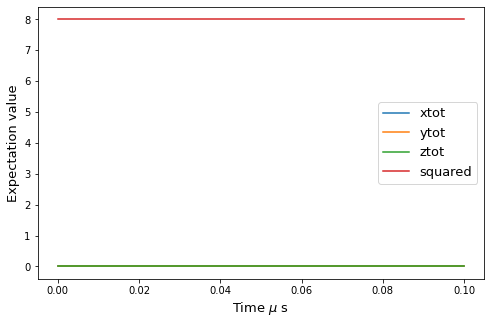

In [62]:
plt.figure(figsize=(8,5))
plt.plot(time/1e-6,np.round(avg_xtot/hbar,2))
plt.plot(time/1e-6,np.round(avg_ytot/hbar,2))
plt.plot(time/1e-6, np.round(avg_ztot/hbar,2))
plt.plot(time/1e-6,np.round(avg_2tot/hbar,2))

plt.ylabel('Expectation value',fontsize=13)   
plt.legend(['xtot','ytot','ztot','squared'],fontsize=13)
plt.xlabel('Time $\mu$ s',fontsize=13)
# plt.ylim(-8,8)


Text(0.5, 0, 'Time (us)')

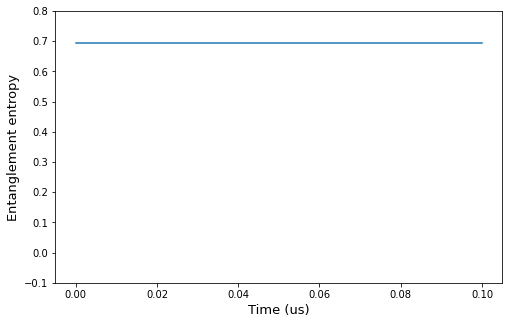

In [65]:
plt.figure(figsize=(8,5))
plt.plot(time/1e-6,Entropy_t)
plt.ylim(-0.1,0.8)
plt.ylabel('Entanglement entropy',fontsize=13)   
plt.xlabel('Time (us)',fontsize=13)   